In [67]:
# This cell is considered my startup cell, inside of it includes: installing the five packages we have been using in class, defining the data location (where im pulling the data from), and importing geopandas, matplotlib, and mapclassify
### - Three hastags comments are the explanation for why I commented out the code that is below it
# I put double spaces between code that does different things (e.g., installing, and importing), triple spaces between code that is used for seperate maps
# (e.g., maps 1 and 2 in Task 1), and used seperate cell blocks for: startup (this cell block),
# Task 1 Map A (seperate the step by step map building required in Task 1 - the maps used after this are in one whole cell block), Task 1 Map B, Bin counts for Maps A and B, and the map for Task 2


# The code below installs the five packages we have been using in class
%pip install -q libpysal esda splot mapclassify contextily


# The next line of code defines the location of where the data I will be using is located
DATA_BASE_P2 = "https://raw.githubusercontent.com/pjbitterman/KSU_x9076/main/data/part2"


### The code below is a local path fallback (for coding without access to internet) - I uncommented it because while typing this code I have internet access
# DATA_BASE_P2 = "../data/part2

# The last part of the startup cell is code that imports geopandas, matplotlib, and mapclassify

# Importing geopandas to read and work with spatial data - We are used to doing this by now
import geopandas as gpd

# Importing mapclassify allows me to bin the data into different classes for different classifications schemes
import mapclassify

# Importing matplotlib is used for creating the map(s) canvas, showing the finalized map, and working with elements of the map like axis and titles
import matplotlib.pyplot as plt

There are 13 columns in the tracts gpkg file and/or dataset:
['GEOID', 'NAME', 'ALAND', 'AWATER', 'median_hh_income', 'pct_poverty', 'pct_bachelors_plus', 'pct_renter_occupied', 'median_gross_rent', 'median_home_value', 'median_age', 'total_population', 'geometry']

For my maps in this sketch, I plan to use 1 column from the 7 ACS columns:
['median_hh_income', 'pct_poverty', 'pct_bachelors_plus', 'pct_renter_occupied', 'median_gross_rent', 'median_home_value', 'median_age']

In the median_age ACS column there are 7 tracts missing out of the 428 total tracts.



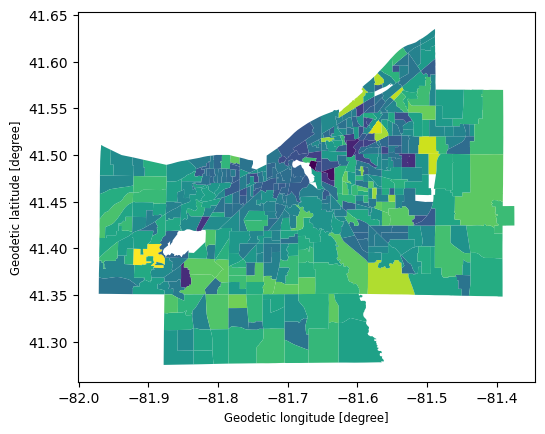

In [68]:
# Task 1


# The code below makes a variable for tracts and stores/assigns the file related to it
# Essentially this code tells Python to go into the previously defined database, pull the cuyahoga tracts acs gpkg and assigns everything it in to the variable of tracts
tracts = gpd.read_file (f"{DATA_BASE_P2}/cuyahoga_tracts_acs.gpkg")


# In class and notebook 12_01 we are given the columns in the dataset - The code below is just a precautionary measure to make sure those are in fact all the columns in the dataset
# I simply used print and then .columns.tolist() to put all the columns in the dataset into an empty list
# After this I made my own seperate list with a variable name to stay more organized - I could have just commented it out but I chose not too
print (f"There are {len(tracts.columns)} columns in the tracts gpkg file and/or dataset:\n{tracts.columns.tolist()}\n")


# The code below is not entirely necessary but I made another list only listing the ACS columns and excluded total_population - I did it to show only the ACS columsn and make it easier to choose which ones I will use for mapping
acs_cols = ["median_hh_income", "pct_poverty", "pct_bachelors_plus", "pct_renter_occupied",
            "median_gross_rent", "median_home_value", "median_age"]

print (f"For my maps in this sketch, I plan to use 1 column from the {len(acs_cols)} ACS columns:\n{acs_cols}")


# The code below makes the variable of column now in order to see how many tracts are missing and then uses (.isna().sum()) in an f-string it calculate it
### I could use either column or COLUMN for the variable name - all caps means it is a constant that will not change throughout the code (like the database), but I stuck with the lowercase because its easier to read
# COLUMN = "median_age"
column = "median_age"

print (f"\nIn the {column} ACS column there are {tracts[column].isna().sum()} tracts missing out of the {len(tracts)} total tracts.\n")


## The code below builds the map step by step - I was not sure if Dr. Bitterman wanted it all in one or step by step because the sketch instructions are misleading ##

#### After step 1 every other step for the first map is in different cell blocks so the resulting maps are not ontop of one another ####

# Step 1: The first step of building my map starts by using features in matplotlib such as .plot() and plt.show() to develop a bare, unlabeled, chloropleth map
tracts.plot(column=column)
plt.show()

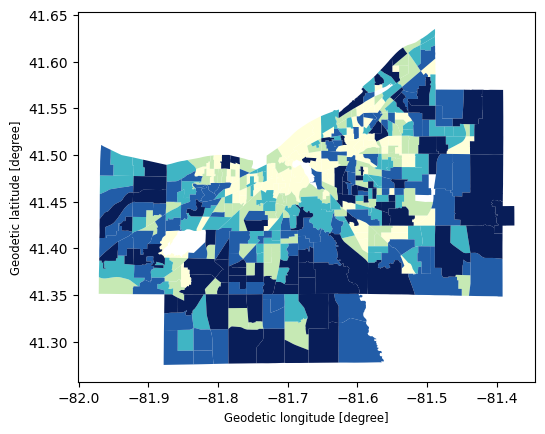

In [69]:
# Step 2: Classifying bins, schemes, cmap, and column name (already defined earlier in the code)

# Again I used .plot to make the plotted map but I added some extra stuff
# Column is just defining the column I want to use (already defined in a variable earlier)
# Scheme is for classification:
# - quantiles cuts the data into bins that each hold about the same amount of tracts
# - equal interval puts data into bins and slices them based on equal width
# - fisher jenks (natural breaks) puts data into bins based on natural gaps between values
# k= is the amount of bins/classes that there will be on the map
# cmap is the color map/scheme - I Yellow, Green, Blues because it seems to be the easiest to see the areas with no data
tracts.plot(
    column=column,
    scheme="quantiles",
    k=5,
    cmap="YlGnBu"
)
plt.show()

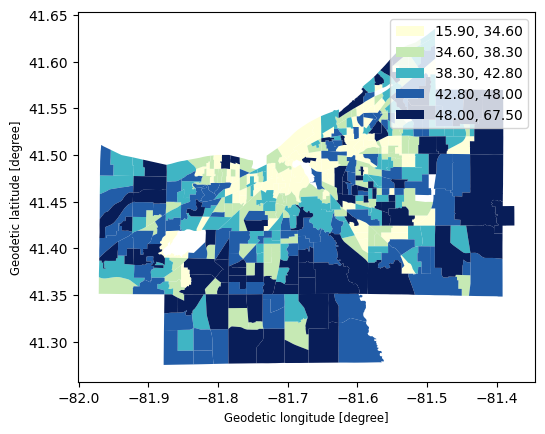

In [70]:
# Step 3: Adds the legend to the map using legend=True

tracts.plot(
    column=column,
    scheme="quantiles",
    k=5,
    cmap="YlGnBu",
    legend=True
)
plt.show()

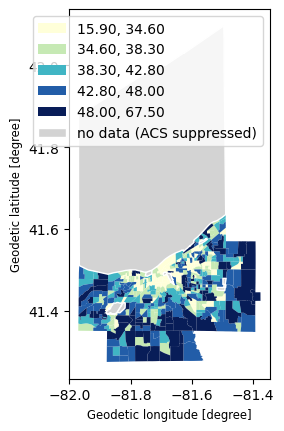

In [71]:
# Step 4: Showing the missing data by assigning it with a different color than the cmap scheme

# This is done by using missing_kwds to tell .plot() what to do with the rows of no data that were set aside (what colors and labels it gets)
tracts.plot(
    column=column,
    scheme="quantiles",
    k=5,
    cmap="YlGnBu",
    legend=True,
    missing_kwds={"color": "lightgrey", "edgecolor": "white", "label": "no data (ACS suppressed)"}
)
plt.show()

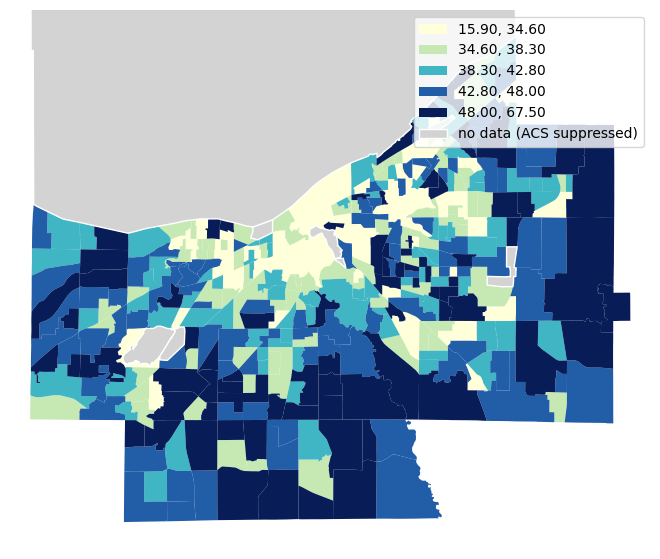

In [72]:
# Step 5: Setting the frame map - In this step we are changing the frame of the map to land tracts because the water tract of Lake Erie is not taking up alot of the figure

# For this we are adding a couple of different things:
# I defined a variable of land and assigned it to the tracts that include an ALAND column to only point to those
# Then I got the min and max for the bounding box the frame will be set too (minx, miny, maxx, maxy)
# After this I created a figure and axis object and adding axis using ax = ax
# Lastly, I set the bounding boxes to the map and made sure to set the axis to off in order to stop bounding box editing that would otherwise most likely cause errors if I had kept it
land = tracts[tracts["ALAND"]>0]
minx, miny, maxx, maxy = land.total_bounds

fig, ax = plt.subplots(figsize=(9,7))
tracts.plot(
    column=column,
    scheme="quantiles",
    k=5,
    cmap="YlGnBu",
    legend=True,
    missing_kwds={"color": "lightgrey", "edgecolor": "white", "label": "no data (ACS suppressed)"},
    ax=ax
)
ax.set_xlim(minx - 0.02, maxx + 0.02)    # 0.02 is the padding used when changing the bounding box for the map
ax.set_ylim(miny - 0.02, maxy + 0.02)
ax.set_axis_off()
plt.show()

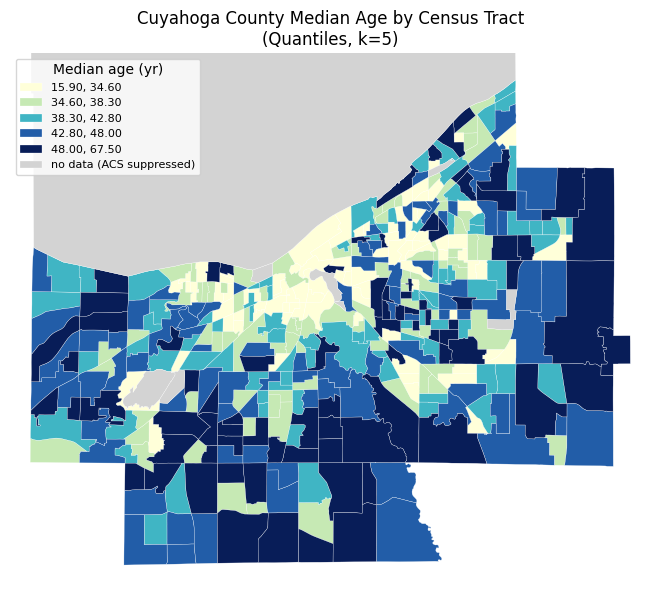

In [73]:
# Step 6: Title addition, legend movement, and boundaries - Also final map for Task 1 Map A

# ax.set_title() sets the title of the whole map
# legend_kwds Adds a legend title with units
# edgecolor sets the color for boundaries between tracts while linewidth sets the width of the line between those tracts
fig, ax = plt.subplots(figsize=(9,7))
tracts.plot(
    column=column,
    scheme="quantiles",
    k=5,
    cmap="YlGnBu",
    legend=True,
    missing_kwds={"color": "lightgrey", "edgecolor": "white", "label": "no data (ACS suppressed)"},
    legend_kwds={"title": "Median age (yr)", "loc": "upper left", "fontsize": 8},
    edgecolor="white",
    linewidth=0.2,
    ax=ax
)
ax.set_xlim(minx - 0.02, maxx + 0.02)    # 0.02 is the padding used when changing the bounding box for the map
ax.set_ylim(miny - 0.02, maxy + 0.02)
ax.set_axis_off()
ax.set_title("Cuyahoga County Median Age by Census Tract\n(Quantiles, k=5)")
fig.savefig("cuyahogaQU_median_age.png", dpi=200, bbox_inches="tight")
plt.show()

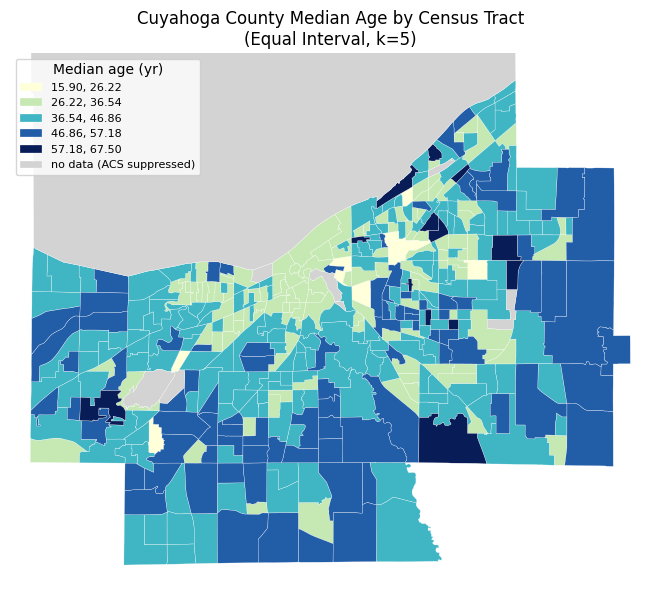

In [75]:
# Task 1 Map B - I used equal intervals for this map

# The only thing I needed to chnage from the previous code cell is the scheme - I already did it step by step so now im just listing the full map with the one small change
fig, ax = plt.subplots(figsize=(9,7))
tracts.plot(
    column=column,
    scheme="equal_interval",
    k=5,
    cmap="YlGnBu",
    legend=True,
    missing_kwds={"color": "lightgrey", "edgecolor": "white", "label": "no data (ACS suppressed)"},
    legend_kwds={"title": "Median age (yr)", "loc": "upper left", "fontsize": 8},
    edgecolor="white",
    linewidth=0.2,
    ax=ax
)
ax.set_xlim(minx - 0.02, maxx + 0.02)    # 0.02 is the padding used when changing the bounding box for the map
ax.set_ylim(miny - 0.02, maxy + 0.02)
ax.set_axis_off()
ax.set_title("Cuyahoga County Median Age by Census Tract\n(Equal Interval, k=5)")
fig.savefig("cuyahogaEI_median_age.png", dpi=200, bbox_inches="tight")
plt.show()

In [81]:
# This code is dedicated towards getting the bin counts of both Map A and Map B

# First I made a variable that only included the bins with values in them
# Next I created two f-strings that each used mapclassify to get the number of tracts that fell into each bin
values = tracts[column].dropna()

print (f"Task 1 Map A (Quantiles, k=5) bin counts:\n{mapclassify.Quantiles(values, k=5)}")
print (f"\nTask 1 Map B (Equal Interval, k=5) bin counts:\n{mapclassify.EqualInterval(values, k=5)}")

Task 1 Map A (Quantiles, k=5) bin counts:
Quantiles

   Interval      Count
----------------------
[15.90, 34.60] |    87
(34.60, 38.30] |    82
(38.30, 42.80] |    84
(42.80, 48.00] |    85
(48.00, 67.50] |    83

Task 1 Map B (Equal Interval, k=5) bin counts:
EqualInterval

   Interval      Count
----------------------
[15.90, 26.22] |    13
(26.22, 36.54] |   118
(36.54, 46.86] |   188
(46.86, 57.18] |    89
(57.18, 67.50] |    13


The quantiles scheme essentially divides the total tract count with values of 421 by the bin cap I set (k=5) by 5 to evenly divide the tracts into the bins by 20%. Equal interval however cuts the data by that same 5 bin limit but also puts it into bins based on width size; hence why the age gap between every bin in equal intervals scheme is 10.32 versus quantiles where it varier per bin. Each scheme has their own negatives and positives in terms of where they could mislead a reader. For example, touching on what I said earlier in the equal intervals scheme the bin count is dispersed showing a majority of the population is beteen age ranges 26.22-46.86. However, when you look at the quantiles scheme this prediction cannot be accurately made as each bin count is almost equal. Another thing that could be misleading is the maps themselves. Map A, the quantile map shows that some people in the age bracket or bin of 48.00-67.50  live on the outskirts of the main city with some residing on the wester side of the city near Lake Erie. However, in Map B, the equal interval map, that same population is split between two bins of 46.86-57.18 and 57.18-67.50, and that darker color indication the higher ages population is no longer there. If someone were doing research with just using the quantiles scheme and made the prediction that people between the ages of 57-67 live on the wester side of the city near Lake Erie they could end up being wrong given what the equal interval map of the same area shows for those age ranges.  

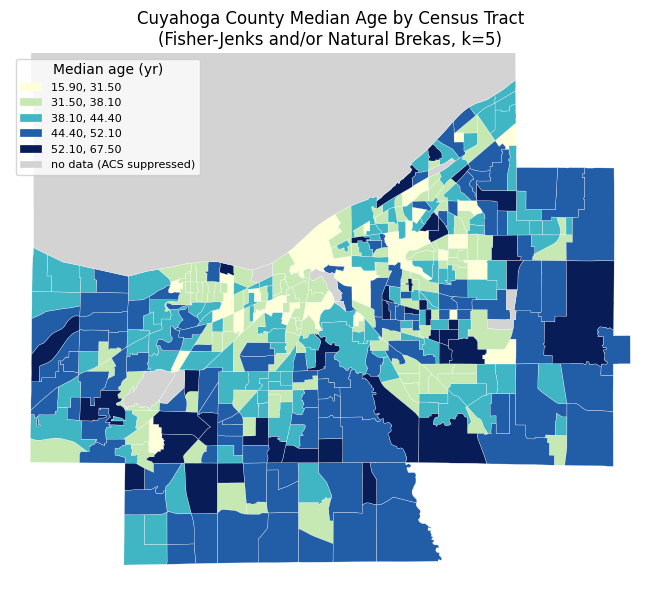


Task 2 Map (Fisher-Jenks, k=5) bin counts:
FisherJenks

   Interval      Count
----------------------
[15.90, 31.50] |    49
(31.50, 38.10] |   113
(38.10, 44.40] |   115
(44.40, 52.10] |   105
(52.10, 67.50] |    39


In [80]:
# Task 2: Fisher-Jenks map and bin count

# The code below follows the same setup as the previous maps with the only change being the addition of fisherjenks in the scheme parameter
# The code below is the map for Task 2
fig, ax = plt.subplots(figsize=(9,7))
tracts.plot(
    column=column,
    scheme="fisherjenks",
    k=5,
    cmap="YlGnBu",
    legend=True,
    missing_kwds={"color": "lightgrey", "edgecolor": "white", "label": "no data (ACS suppressed)"},
    legend_kwds={"title": "Median age (yr)", "loc": "upper left", "fontsize": 8},
    edgecolor="white",
    linewidth=0.2,
    ax=ax
)
ax.set_xlim(minx - 0.02, maxx + 0.02)    # 0.02 is the padding used when changing the bounding box for the map
ax.set_ylim(miny - 0.02, maxy + 0.02)
ax.set_axis_off()
ax.set_title("Cuyahoga County Median Age by Census Tract\n(Fisher-Jenks and/or Natural Brekas, k=5)")
fig.savefig("cuyahogaFJ_median_age.png", dpi=200, bbox_inches="tight")
plt.show()

# The code below is the bin count for this map
print (f"\nTask 2 Map (Fisher-Jenks, k=5) bin counts:\n{mapclassify.FisherJenks(values, k=5)}")

I would use the fisher-jenks scheme over the quantiles and equal interval schemes when I want to focus on groups of individuals. For example, if I were a health planner who was trying the find areas that are best suited for builidng a hospital or a type senior service center, I would use this fisher-jenks map in combination with population data to find an area most suited for that building type. Because this scheme type is focused on finding natural gaps in the data, it is alot more effective at showing data that may be missed due to equal spreading in a scheme like quantiles.

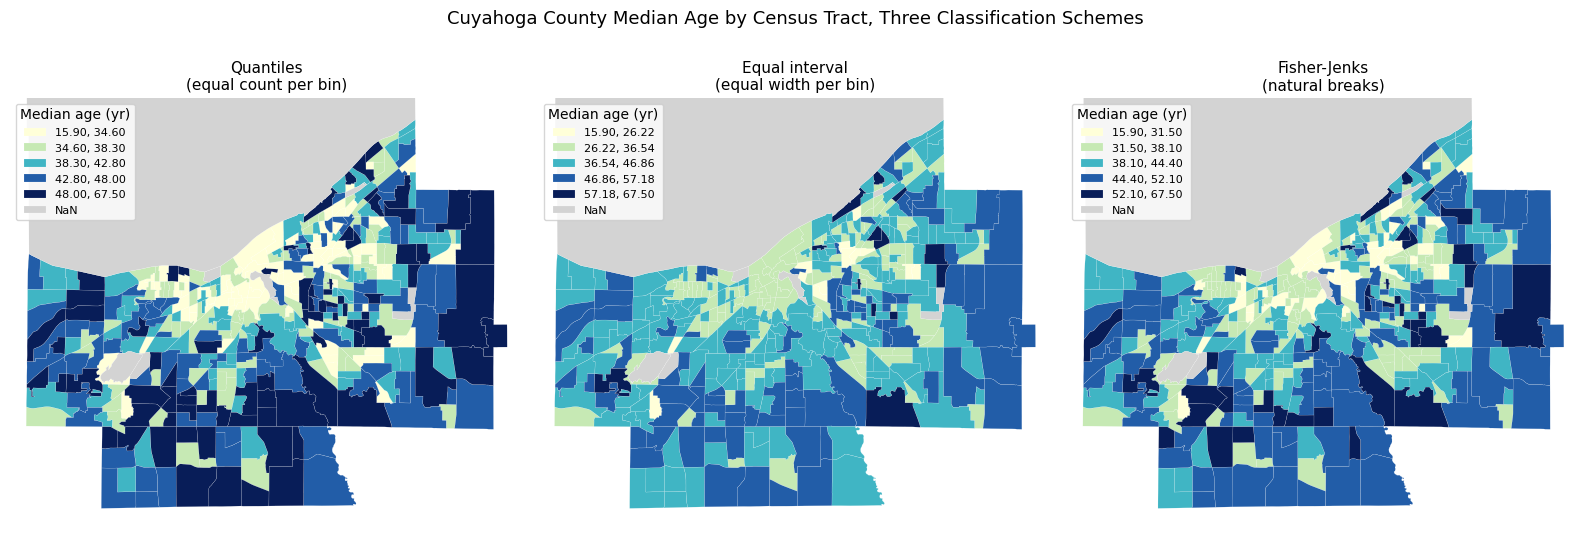

quantiles [np.int64(87), np.int64(82), np.int64(84), np.int64(85), np.int64(83)]
equal_interval [np.int64(13), np.int64(118), np.int64(188), np.int64(89), np.int64(13)]
fisher_jenks [np.int64(49), np.int64(113), np.int64(115), np.int64(105), np.int64(39)]


In [78]:
# Extra self assigned Task: Im very OCD so here are all three maps side by side for comparison
#### Mind you I copy and pasted this code directly from the notebook and onyl changed things like the titles and column names ####

fig, axes = plt.subplots(1, 3, figsize=(16, 6))
schemes = ["quantiles", "equal_interval", "fisher_jenks"]
titles = ["Quantiles\n(equal count per bin)", "Equal interval\n(equal width per bin)", "Fisher-Jenks\n(natural breaks)"]

for ax, scheme, title in zip(axes, schemes, titles):
    tracts.plot(
        column=column,
        scheme=scheme,
        k=5,
        cmap="YlGnBu",
        ax=ax,
        legend = True,
        missing_kwds={"color": "lightgrey", "edgecolor": "white"},
        legend_kwds={"title": "Median age (yr)", "loc": "upper left", "fontsize": 8},
        edgecolor="white",
        linewidth=0.1,
    )
    ax.set_title(title, fontsize=11)
    ax.set_xlim(minx - 0.02, maxx + 0.02)
    ax.set_ylim(miny - 0.02, maxy + 0.02)
    ax.set_axis_off()


fig.suptitle("Cuyahoga County Median Age by Census Tract, Three Classification Schemes", fontsize=13)
plt.tight_layout()
plt.show()

for scheme in schemes:
    cls = getattr(mapclassify, {"quantiles": "Quantiles", "equal_interval": "EqualInterval", "fisher_jenks": "FisherJenks"}[scheme])
    print(scheme, list(cls(tracts[column].dropna(), k=5).counts))